In [1]:
get_ipython().run_line_magic("load_ext", "autoreload")  # dev-only
get_ipython().run_line_magic("autoreload", "2")  # dev-only

# Лабораторная работа 1. Нейронные сети для табличных данных

## Постановка задачи

Мультиклассовая классификация оценки `quality` (3–8) красного вина по 11 физико-химическим признакам (UCI Wine Quality). Основная метрика — F1 macro (выбор моделей по val); дополнительно balanced accuracy, F1 weighted и ROC AUC OvR.

Протокол: одно разбиение train/val/test = 1023/256/320. Test тот же, что в ml-2 ЛР1 (stratified 20 %, `random_state=42`). Preprocessing учится только на train, test используется только для итоговой оценки.

Модели: CatBoost (baseline), FT-Transformer, GANDALF (часть I), TabLDM, TabM (часть II).

Все результаты в ноутбуке получены полными прогонами. Быстрый режим (аналог `FAST_MODE = True`) использовался только для проверки pipeline.

# I. Нейронные сети для табличных данных по учебным примерам

## 1.1 Набор данных

UCI Wine Quality (красное вино): 1599 объектов, 11 числовых признаков, категориальных нет. Полный EDA сделан в ml-2 ЛР1, здесь только итог: классы качества и их дисбаланс, связь признаков с `quality`.

In [2]:
import plotly.express as px

from src.data import TARGET, load_raw

df = load_raw()
print(df.shape)

counts = df[TARGET].value_counts().sort_index()
fig = px.bar(x=counts.index.astype(str), y=counts.values, text=counts.values)
fig.update_layout(
    title="Распределение классов quality", xaxis_title="quality", yaxis_title="число объектов"
)
fig.show()

corr = df.corr()[TARGET].drop(TARGET).sort_values()
fig = px.bar(x=corr.values, y=corr.index, orientation="h")
fig.update_layout(
    title="Корреляция Пирсона признаков с quality", xaxis_title="корреляция", yaxis_title="признак"
)
fig.show()

(1599, 12)


> **Вывод:**

Картина та же, что и в ml-2 ЛР1: классы `5` и `6` вместе дают 1319 из 1599 объектов, а крайние оценки почти не представлены — `quality=3` всего 10 раз, `quality=8` — 18. Из-за такого дисбаланса `accuracy` здесь мало что говорит, поэтому основной метрикой остается `F1 macro`, где каждый из 6 классов весит одинаково.

Линейная связь с таргетом сильнее всего у `alcohol` (+0.476) и `volatile acidity` (−0.391), дальше идут `sulphates` (+0.251) и `citric acid` (+0.226), а `residual sugar` почти не связан с `quality` (0.014). При этом даже лучшая корреляция далека от единицы, так что, вероятно, качество определяется комбинацией признаков, а не одним из них — для бустинга и нейросетей это нормальная ситуация.

## 1.2 Предварительная обработка и baseline

- Признаки: 11 исходных + 5 производных из ml-2 ЛР1: `total_acidity` = fixed acidity + volatile acidity + citric acid; `vol_fixed_ratio` = volatile acidity / fixed acidity; `free_so2_ratio` = free SO2 / total SO2; `alc_density_prod` = alcohol · density; `sugar_alc_ratio` = residual sugar / alcohol.
- Разбиение: stratified, train/val/test = 1023/256/320, test как в ml-2 ЛР1 (`random_state=42`).
- Масштабирование: у каждой нейросети своё, обучается на train. CatBoost инвариантен к монотонным преобразованиям признаков.
- Baseline: CatBoost с параметрами Optuna из ml-2 ЛР1, `auto_class_weights='Balanced'`, early stopping по val. Обучение в `src/train.py` → `runs/v1/`, ноутбук только читает ран.

In [3]:
import pandas as pd

from src.data import CLASSES, TARGET, load_splits

train_df, val_df, test_df = load_splits()
sizes = pd.DataFrame(
    {
        name: part[TARGET].value_counts().reindex(CLASSES, fill_value=0)
        for name, part in [("train", train_df), ("val", val_df), ("test", test_df)]
    }
).T
sizes["всего"] = sizes.sum(axis=1)
sizes

quality,3,4,5,6,7,8,всего
train,6,34,436,408,127,12,1023
val,2,8,109,102,32,3,256
test,2,11,136,128,40,3,320


In [4]:
from sklearn.dummy import DummyClassifier

from src.data import to_xy
from src.train import compute_metrics

X_train, y_train = to_xy(train_df)
dummy = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
dummy_rows = {}
for name, part in [("val", val_df), ("test", test_df)]:
    X, y = to_xy(part)
    dummy_rows[f"Dummy (most_frequent), {name}"] = compute_metrics(
        y, dummy.predict(X), dummy.predict_proba(X)
    )
pd.DataFrame(dummy_rows).T

/Users/2madeira/dev/maga/third/ml-3/lab-1/.venv/lib/python3.13/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


,f1_macro,balanced_acc,f1_weighted,roc_auc_ovr
"Dummy (most_frequent), val",0.099543,0.166667,0.254302,0.5
"Dummy (most_frequent), test",0.099415,0.166667,0.253509,0.5


In [5]:
from src.plots import plot_confusion, plot_curves
from src.results import load_run

run = load_run("v1")
names = ["f1_macro", "balanced_acc", "f1_weighted", "roc_auc_ovr"]
cb_rows = {f"CatBoost, {s}": {k: run.metrics[f"{s}_{k}"] for k in names} for s in ("val", "test")}
ref_rows = {
    "RF baseline, ml-2 ЛР1, test (справочно)": dict(
        f1_macro=0.4023, balanced_acc=0.3870, f1_weighted=0.6697, roc_auc_ovr=0.8091
    ),
    "CatBoost Optuna, ml-2 ЛР1, test (справочно)": dict(
        f1_macro=0.3532, balanced_acc=0.4119, f1_weighted=0.5787, roc_auc_ovr=0.7887
    ),
}
pd.DataFrame({**dummy_rows, **cb_rows, **ref_rows}).T

,f1_macro,balanced_acc,f1_weighted,roc_auc_ovr
"Dummy (most_frequent), val",0.099543,0.166667,0.254302,0.500000
"Dummy (most_frequent), test",0.099415,0.166667,0.253509,0.500000
"CatBoost, val",0.292520,0.334266,0.527425,0.733936
"CatBoost, test",0.329339,0.373781,0.550047,0.797835
"RF baseline, ml-2 ЛР1, test (справочно)",0.402300,0.387000,0.669700,0.809100
"CatBoost Optuna, ml-2 ЛР1, test (справочно)",0.353200,0.411900,0.578700,0.788700


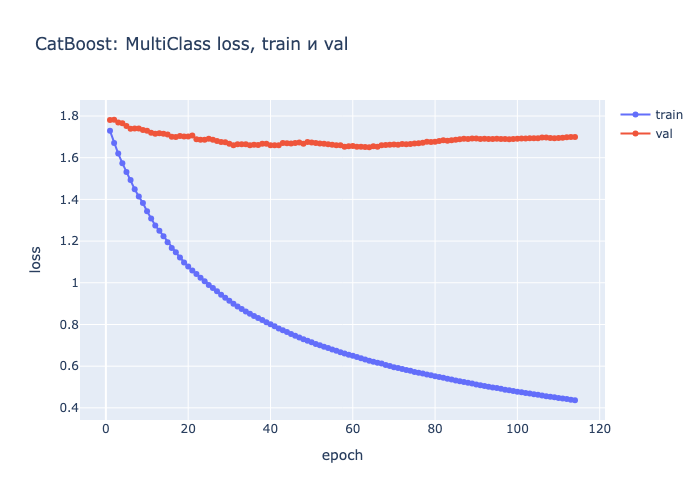

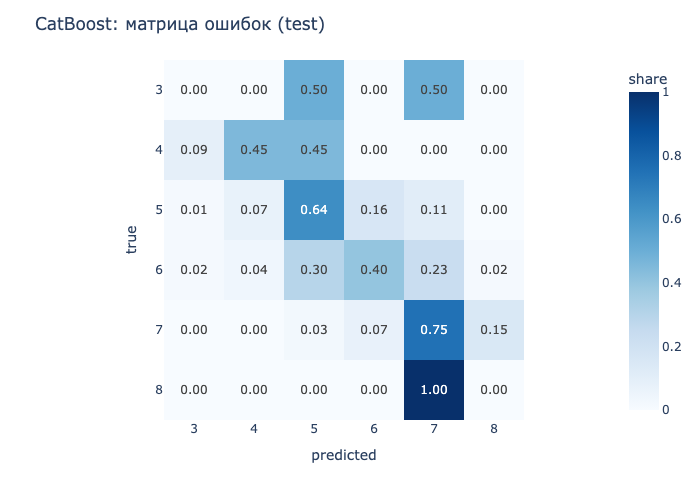

In [6]:
fig = plot_curves(run.history, "loss", title="CatBoost: MultiClass loss, train и val")
fig.show()
fig = plot_confusion(
    run.predictions, labels=[str(c) for c in CLASSES], title="CatBoost: матрица ошибок (test)"
)
fig.show()

> **Вывод:**

`CatBoost` дал `F1 macro` 0.2925 на val и 0.3293 на test против 0.0995 у `Dummy`, так что модель действительно что-то выучила, а не просто угадывает частый класс. Однако до `CatBoost Optuna` из ml-2 ЛР1 (0.3532 на test) она не дотягивает. Я посчитал это ожидаемым: здесь train меньше на 256 объектов, которые ушли в val, а в ml-2 ЛР1 early stopping шел прямо по test, то есть test участвовал в выборе итерации. Честно говоря, до меня это дошло только сейчас, когда пришлось заводить отдельную валидацию.

Кривые показывают переобучение довольно рано: минимум val loss на 64-й итерации (1.6505), дальше он растет, хотя train loss продолжает падать до 0.4365. Весь `F1 macro` держится на классах `4`–`7`, а `3` и `8` модель не угадала ни разу — при 2 и 3 объектах в test это и неудивительно. `auto_class_weights='Balanced'` заметно тянет модель к редким классам: у `quality=7` recall 0.750 при precision 0.380, то есть класс находится, но ценой ложных срабатываний из соседнего `6`. Если говорить по простому — val в 256 объектов слишком мал для устойчивой оценки, поэтому сравнивать с нейросетями дальше стоит на нескольких seeds.

## 1.3 FT-Transformer и GANDALF «из коробки»

- Идея `FT-Transformer`: каждый числовой признак своей линейной проекцией превращается в отдельный вектор-токен, к ним добавляется `[CLS]`, и стек transformer-блоков через self-attention учит взаимодействия между признаками. Предсказание снимается с выхода `[CLS]`. По сути это ViT для таблиц, где токен — один признак.
- Идея `GANDALF`: сеть из нескольких стадий Gated Feature Learning Unit (`GFLU`). На каждой стадии обучаемая разреженная маска (`t-softmax`) выбирает подмножество признаков, а гейты, как в `GRU`, решают, что взять из нового представления и что оставить с прошлой стадии. Получается компактная сеть со встроенным отбором признаков, по духу ближе к деревьям, чем к attention.

Обе модели обучены через `pytorch_tabular` с параметрами библиотеки по умолчанию: `Adam`, `lr=1e-3`, `batch_size=64`, обычная `CrossEntropy` без весов классов, early stopping по val loss с `patience=20`, масштабирование признаков обучается на train.

In [7]:
ft_run = load_run("v2")
gandalf_run = load_run("v3")
cb_run = load_run("v1")
cols = [
    "модель",
    "архитектура",
    "эпох обучено",
    "лучшая эпоха",
    "val F1 macro",
    "val balanced acc",
    "время, с",
    "параметров",
]
rows = []
for name, r in [("FT-Transformer", ft_run), ("GANDALF", gandalf_run)]:
    c = r.config
    arch = (
        f"embed {c['ft_embed_dim']}, heads {c['ft_num_heads']}, blocks {c['ft_num_attn_blocks']}"
        if name == "FT-Transformer"
        else f"stages {c['gandalf_stages']}, dropout {c['gandalf_dropout']}"
    )
    rows.append(
        [
            name,
            arch,
            len(r.history),
            r.metrics["best_epoch"],
            r.metrics["val_f1_macro"],
            r.metrics["val_balanced_acc"],
            r.metrics["train_time_sec"],
            r.metrics["n_params"],
        ]
    )
rows.append(
    [
        "CatBoost (v1)",
        f"depth {cb_run.config['cb_depth']}",
        len(cb_run.history),
        cb_run.metrics["best_iteration"] + 1,  # CatBoost считает итерации с 0
        cb_run.metrics["val_f1_macro"],
        cb_run.metrics["val_balanced_acc"],
        cb_run.metrics["train_time_sec"],
        None,
    ]
)
pd.DataFrame(rows, columns=cols)

,модель,архитектура,эпох обучено,лучшая эпоха,val F1 macro,val balanced acc,"время, с",параметров
0,FT-Transformer,"embed 32, heads 8, blocks 6",32,12,0.274227,0.271519,10.234089,272614.0
1,GANDALF,"stages 6, dropout 0.0",52,32,0.278200,0.278668,8.766092,9746.0
2,CatBoost (v1),depth 10,114,64,0.292520,0.334266,2.075133,NaN


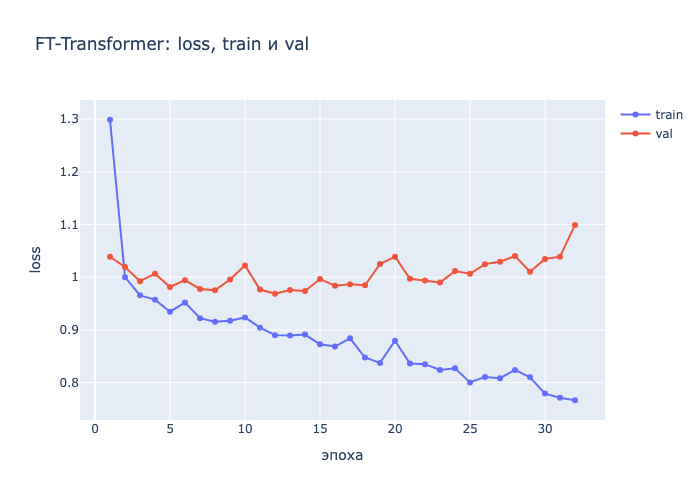

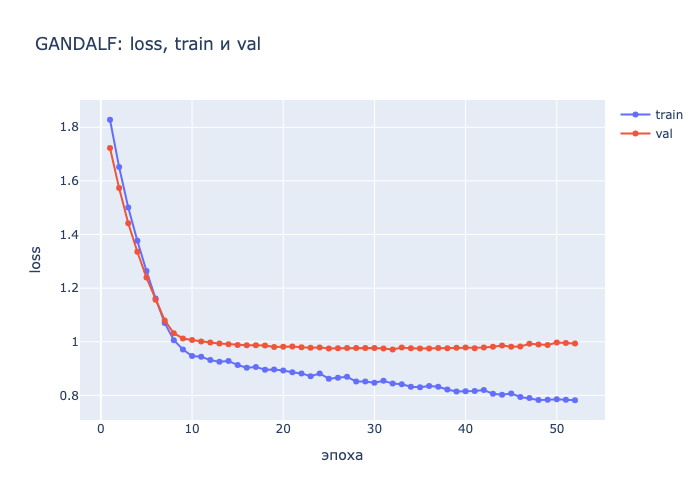

In [8]:
for name, r in [("FT-Transformer", ft_run), ("GANDALF", gandalf_run)]:
    fig = plot_curves(r.history, "loss", title=f"{name}: loss, train и val")
    fig.update_layout(xaxis_title="эпоха", yaxis_title="loss")
    fig.show()

> **Вывод:**

Обе нейросети «из коробки» оказались примерно на одном уровне: `F1 macro` на val 0.2742 у `FT-Transformer` и 0.2782 у `GANDALF`, то есть сильно выше `Dummy` (0.0995), но немного ниже `CatBoost` (0.2925). При этом `GANDALF` добился этого с 9746 параметрами против 272614 у `FT-Transformer` — разница почти в 28 раз. Разрыв с бустингом сильнее всего виден по `balanced accuracy`: 0.2715 и 0.2787 у нейросетей против 0.3343 у `CatBoost`. Основная причина, вероятно, не в архитектурах, а в loss: у нейросетей обычная `CrossEntropy` без весов, и обе почти все предсказания отдают классам `5` и `6` (307 и 298 из 320 объектов test), тогда как `CatBoost` с `auto_class_weights='Balanced'` чаще рискует на редких классах.

Кривые обучения показывают, что большой `FT-Transformer` переобучается быстро: минимум val loss уже на 12-й эпохе (0.9685), дальше он растет до 1.0992, хотя train loss продолжает падать. У `GANDALF` картина более здоровая — минимум на 32-й эпохе (0.9715) и рост после него заметно мягче. На 1023 объектах 6 transformer-блоков, в целом ожидаемо, избыточны. Отдельно отмечу, что сначала `pytorch_tabular` молча игнорировал seed из конфига (`fit` подставляет свой `seed=42`), и это всплыло только на sanity-проверке, когда loss на старте совпал до четвертого знака при разных seeds. Дальше в 1.4 первым делом стоит попробовать веса классов в loss и подобрать `lr`, а для `FT-Transformer` — уменьшить модель или усилить dropout.

## 1.4 Исследование и оптимизация моделей

Сначала для каждой модели подобран `lr` (вместе с `weight_decay` как nuisance-параметром) через Optuna TPE: 20 trials на модель, целевая метрика — val F1 macro (studies `runs/tune/tune-gandalf-lr.db`, `runs/tune/tune-ft-lr.db`). Затем поверх подобранного `lr` проверяется по одной гипотезе за итерацию. Выбор конфигурации идет только по val F1 macro, test показан справочно.

In [9]:
def lr_wd(run):
    return f"lr {run.config['lr']:g}, wd {run.config['weight_decay']:g}"


experiments = [
    ("GANDALF", "v3", "из коробки", lr_wd, "точка отсчета"),
    (
        "GANDALF",
        "v4",
        "lr влияет сильнее всего",
        lambda r: lr_wd(r) + " (Optuna)",
        "+0.0125 к v3, но меньше разброса trials (0.03)",
    ),
    (
        "GANDALF",
        "v6",
        "веса классов помогут редким классам",
        lambda r: f"class_weights {r.config['class_weights']}",
        "не подтвердилась: −0.060 к v4",
    ),
    (
        "GANDALF",
        "v8",
        "dropout снизит переобучение",
        lambda r: f"dropout 0.0 → {r.config['gandalf_dropout']:g}",
        "val loss ниже, F1 macro в пределах шума",
    ),
    ("FT-Transformer", "v2", "из коробки", lr_wd, "точка отсчета"),
    (
        "FT-Transformer",
        "v5",
        "lr влияет сильнее всего",
        lambda r: lr_wd(r) + " (Optuna)",
        "+0.019 к v2; lr ≥ 6.9e-3 расходится",
    ),
    (
        "FT-Transformer",
        "v7",
        "веса классов помогут редким классам",
        lambda r: f"class_weights {r.config['class_weights']}",
        "не подтвердилась: обучение нестабильно, −0.092 к v5",
    ),
    (
        "FT-Transformer",
        "v9",
        "меньшая модель переобучится меньше",
        lambda r: (
            f"embed 32 → {r.config['ft_embed_dim']}, blocks 6 → {r.config['ft_num_attn_blocks']}, "
            f"ff_dropout 0.1 → {r.config['ft_ff_dropout']:g}"
        ),
        "не подтвердилась: −0.050 к v5, переобучение раньше",
    ),
]
rows = []
for model, name, hypothesis, values, verdict in experiments:
    r = load_run(name)
    rows.append(
        [
            model,
            name,
            hypothesis,
            values(r),
            round(r.metrics["val_f1_macro"], 4),
            r.metrics["best_epoch"],
            verdict,
        ]
    )
pd.DataFrame(
    rows,
    columns=[
        "модель",
        "ран",
        "гипотеза",
        "значения",
        "val F1 macro",
        "лучшая эпоха",
        "вывод",
    ],
)

,модель,ран,гипотеза,значения,val F1 macro,лучшая эпоха,вывод
0,GANDALF,v3,из коробки,"lr 0.001, wd 0.0001",0.2782,32,точка отсчета
1,GANDALF,v4,lr влияет сильнее всего,"lr 0.005, wd 1e-05 (Optuna)",0.2907,9,"+0.0125 к v3, но меньше разброса trials (0.03)"
2,GANDALF,v6,веса классов помогут редким классам,class_weights balanced,0.2307,4,не подтвердилась: −0.060 к v4
3,GANDALF,v8,dropout снизит переобучение,dropout 0.0 → 0.2,0.2875,20,"val loss ниже, F1 macro в пределах шума"
4,FT-Transformer,v2,из коробки,"lr 0.001, wd 0.0001",0.2742,12,точка отсчета
5,FT-Transformer,v5,lr влияет сильнее всего,"lr 0.004, wd 5e-06 (Optuna)",0.2933,28,+0.019 к v2; lr ≥ 6.9e-3 расходится
6,FT-Transformer,v7,веса классов помогут редким классам,class_weights balanced,0.2010,10,"не подтвердилась: обучение нестабильно, −0.092..."
7,FT-Transformer,v9,меньшая модель переобучится меньше,"embed 32 → 16, blocks 6 → 3, ff_dropout 0.1 → 0.3",0.2433,6,"не подтвердилась: −0.050 к v5, переобучение ра..."


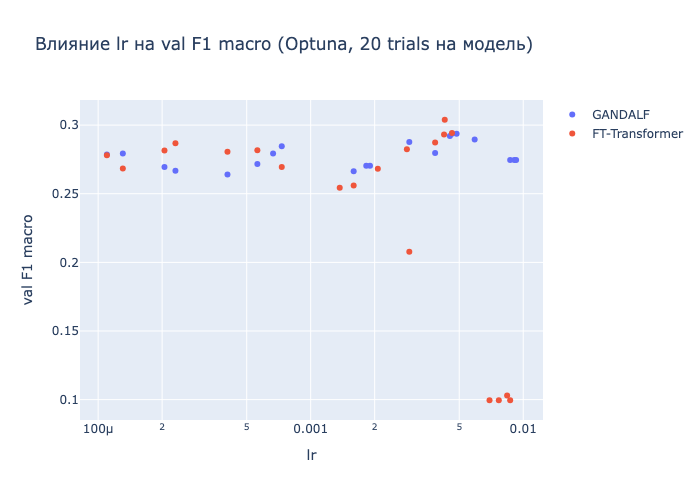

In [10]:
import optuna
import plotly.graph_objects as go

optuna.logging.set_verbosity(optuna.logging.WARNING)

fig = go.Figure()
for model, name in [("GANDALF", "tune-gandalf-lr"), ("FT-Transformer", "tune-ft-lr")]:
    study = optuna.load_study(study_name=name, storage=f"sqlite:///runs/tune/{name}.db")
    trials = [t for t in study.trials if t.state == optuna.trial.TrialState.COMPLETE]
    fig.add_trace(
        go.Scatter(
            x=[t.params["lr"] for t in trials],
            y=[t.value for t in trials],
            mode="markers",
            name=model,
        )
    )
fig.update_layout(
    title="Влияние lr на val F1 macro (Optuna, 20 trials на модель)",
    xaxis_title="lr",
    yaxis_title="val F1 macro",
    xaxis_type="log",
)
fig.show()

In [11]:
rows = []
for model, name in [("GANDALF", "v4"), ("FT-Transformer", "v5")]:
    r = load_run(name)
    c = r.config
    arch = (
        f"embed {c['ft_embed_dim']}, heads {c['ft_num_heads']}, blocks {c['ft_num_attn_blocks']}"
        if model == "FT-Transformer"
        else f"stages {c['gandalf_stages']}, dropout {c['gandalf_dropout']}"
    )
    rows.append(
        [
            model,
            name,
            c["lr"],
            c["weight_decay"],
            arch,
            round(r.metrics["val_f1_macro"], 4),
            round(r.metrics["test_f1_macro"], 4),
        ]
    )
pd.DataFrame(
    rows,
    columns=[
        "модель",
        "ран",
        "lr",
        "weight_decay",
        "архитектура",
        "val F1 macro",
        "test F1 macro (справочно)",
    ],
)

,модель,ран,lr,weight_decay,архитектура,val F1 macro,test F1 macro (справочно)
0,GANDALF,v4,0.005,0.000010,"stages 6, dropout 0.0",0.2907,0.3041
1,FT-Transformer,v5,0.004,0.000005,"embed 32, heads 8, blocks 6",0.2933,0.2962


> **Вывод:**

Главный рычаг у обеих моделей оказался в `lr`: после Optuna `GANDALF` вырос с 0.2782 до 0.2907 по val `F1 macro`, `FT-Transformer` — с 0.2742 до 0.2933, и обе нейросети вышли на уровень `CatBoost` (0.2925). Однако прирост 0.0125–0.019 сопоставим с разбросом самих trials (у `GANDALF` 0.264–0.294 на одном seed), так что честнее говорить «догнали бустинг», а не «обогнали». При этом у `FT-Transformer` рабочая область `lr` узкая: при `lr` ≥ 6.9e-3 обучение расходится и модель скатывается в один класс (0.0995–0.1031, уровень `Dummy`), а выбранные 4e-3 оставляют запас меньше чем в 2 раза.

Остальные гипотезы не подтвердились. Веса классов `balanced` уронили `F1 macro` до 0.2307 у `GANDALF` и до 0.2010 у `FT-Transformer`: `GANDALF` начал предсказывать класс `3` 42 раза при 2 истинных объектах в test, а `FT-Transformer` с весами до 28.4 просто вышел за устойчивую область `lr` и обучение развалилось. Вообще, этот результат меня удивил: после этапа 1.3 я был уверен, что отставание нейросетей по `balanced accuracy` объясняется именно loss без весов, но при 7 и 14 объектах классов `3` и `8` в train веса учат модель запоминать эти объекты, а не отличать классы. Dropout 0.2 у `GANDALF` сдвинул лучшую эпоху с 9 на 20 и снизил val loss с 0.9655 до 0.9481, но `F1 macro` остался в пределах шума (0.2875), а уменьшенный в 8 раз `FT-Transformer` (34 726 параметров против 272 614) переобучился даже раньше и дал 0.2433 на val.

Если говорить по простому - `F1 macro` здесь упирается не в переобучение и не в архитектуру, а в классы `3` и `8`, которые ни одна конфигурация так и не научилась правильно предсказывать. Показателен `v9`: на test у него лучший `F1 macro` среди нейросетей (0.3204) при худшем val, то есть на 2–3 объектах редких классов метрика сильно шумит, и выбор по val здесь единственный честный вариант. Поэтому в дальнейшее сравнение идут `GANDALF v4` и `FT-Transformer v5`.

## 1.5 Сравнение моделей и их поведение

Финальные модели — перезапуски `v10`–`v12` с конфигурациями `v1` (CatBoost), `v4` (GANDALF) и `v5` (FT-Transformer): в 1.2–1.4 это лучшие конфигурации каждой модели по val `F1 macro`. Перезапуск нужен, чтобы в рана попали permutation importance, встроенный importance и предсказания на объектах, созданных вручную. Test используется только для итоговой оценки и анализа, выбор конфигураций шел по val.

### Test

In [12]:
FINAL = {"CatBoost": "v10", "GANDALF": "v11", "FT-Transformer": "v12"}
final_runs = {model: load_run(name) for model, name in FINAL.items()}

metric_names = {
    "f1_macro": "test F1 macro",
    "balanced_acc": "test balanced acc",
    "f1_weighted": "test F1 weighted",
    "roc_auc_ovr": "test ROC AUC OvR",
}
rows = {}
for model, r in final_runs.items():
    rows[f"{model} ({FINAL[model]})"] = {
        "val F1 macro": r.metrics["val_f1_macro"],
        **{title: r.metrics[f"test_{k}"] for k, title in metric_names.items()},
        "время обучения, с": r.metrics["train_time_sec"],
        "параметров": r.metrics.get("n_params"),  # у CatBoost нет
    }
reference = {"Dummy (most_frequent)": dummy_rows["Dummy (most_frequent), test"], **ref_rows}
for name, m in reference.items():
    rows[name] = {title: m[k] for k, title in metric_names.items()}
pd.DataFrame(rows).T

,val F1 macro,test F1 macro,test balanced acc,test F1 weighted,test ROC AUC OvR,"время обучения, с",параметров
CatBoost (v10),0.292520,0.329339,0.373781,0.550047,0.797835,2.130627,NaN
GANDALF (v11),0.290736,0.304146,0.290014,0.568203,0.748158,4.927702,9746.0
FT-Transformer (v12),0.289173,0.303166,0.302497,0.583022,0.762566,10.822204,272614.0
Dummy (most_frequent),NaN,0.099415,0.166667,0.253509,0.500000,NaN,NaN
"RF baseline, ml-2 ЛР1, test (справочно)",NaN,0.402300,0.387000,0.669700,0.809100,NaN,NaN
"CatBoost Optuna, ml-2 ЛР1, test (справочно)",NaN,0.353200,0.411900,0.578700,0.788700,NaN,NaN


> **Вывод:**

На test впереди остался `CatBoost`: `F1 macro` 0.3293 против 0.3041 у `GANDALF` и 0.3032 у `FT-Transformer`, по `balanced accuracy` отрыв ещё больше (0.3738 против 0.2900 и 0.3025), по `ROC AUC OvR` тоже (0.7978 против 0.7482 и 0.7626). При этом по `F1 weighted` картина обратная: нейросети дают 0.5830 и 0.5682 против 0.5500 у бустинга. На val все три модели стоят в пределах 0.0033 (0.2925 / 0.2907 / 0.2892), а повтор `v5` в `v12` с тем же seed сдвинул val `F1 macro` на 0.004, так что разница на val — это шум, а отрыв на test в 0.025 держится в основном на объектах редких классов (2 объекта класса `3`, 11 — класса `4`, 3 — класса `8`).

По сравнению с ml-2 ЛР1 все три модели ниже справочного `RF` (0.4023) и `CatBoost` (0.3532) на том же test, но сравнение это не совсем честное. Там модели учились на всех 1279 объектах без val, а здесь 256 из них ушли на early stopping. Кроме того, `CatBoost` в ml-2 делал early stopping по `eval_set=(X_test, y_test)`, то есть лучшая итерация выбиралась прямо по test, так что его 0.3532 завышено. А `F1 macro` 0.4023 у `RF` почти целиком держится на классе `8`: лес угадал 1 из 3 его объектов (F1 0.40), и одно это даёт +0.067 к среднему по 6 классам. Без класса `8` было бы 0.337, то есть уровень нашего `CatBoost` (0.3293). Зато на частых классах `5` и `6` `RF` действительно сильнее (F1 0.75 и 0.69 против 0.649 и 0.500 у `CatBoost v10`), отсюда и его `F1 weighted` 0.6697.

В целом для табличных данных такого размера результат ожидаемый: нейросети догнали бустинг по val, но не обогнали его, а стоят дороже — 4.9 и 10.8 с обучения против 2.1 с, у `FT-Transformer` 272 614 параметров.

### Анализ ошибок

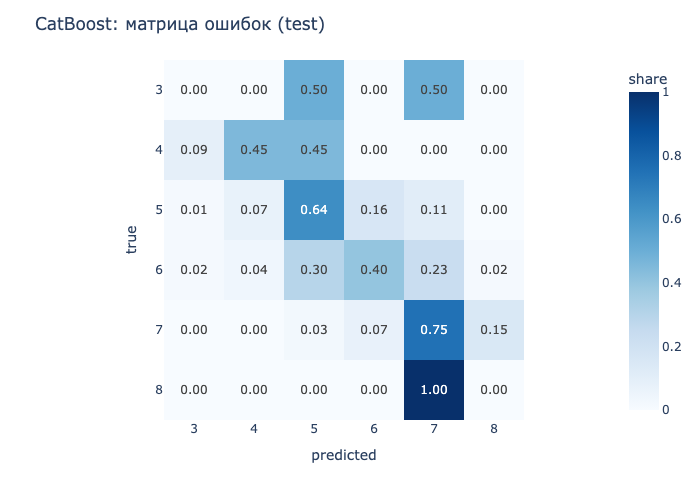

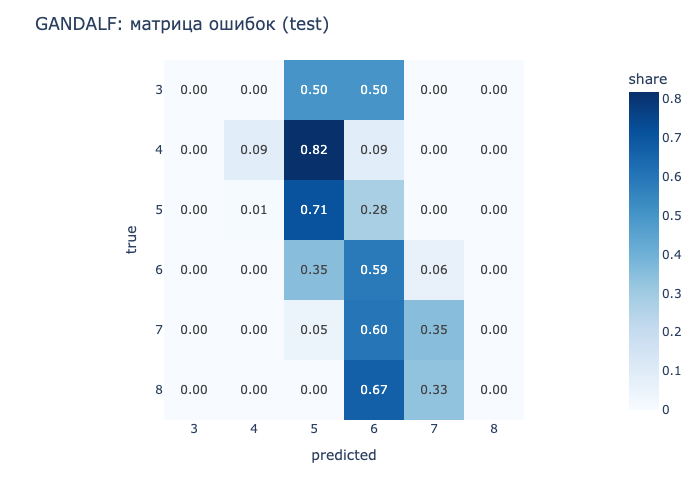

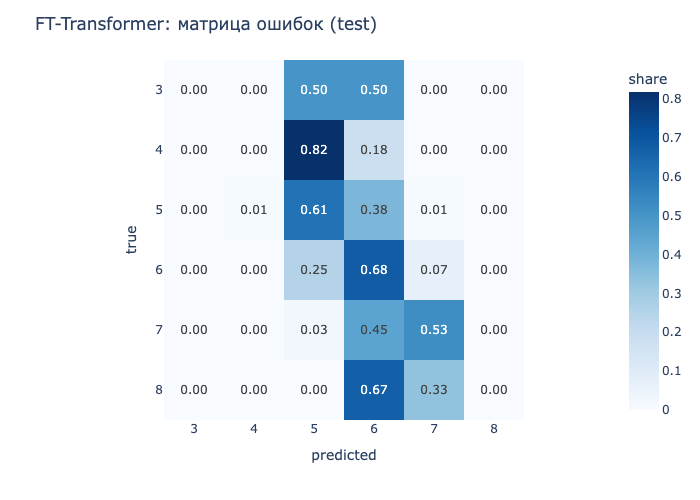

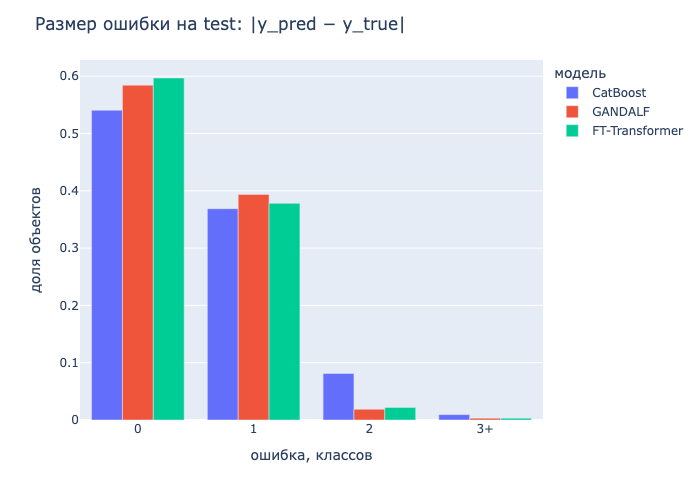

,CatBoost,GANDALF,FT-Transformer,support
recall по классам,,,,
3,0.000000,0.000000,0.000000,2
4,0.454545,0.090909,0.000000,11
5,0.639706,0.713235,0.610294,136
6,0.398438,0.585938,0.679688,128
7,0.750000,0.350000,0.525000,40
8,0.000000,0.000000,0.000000,3


In [13]:
import plotly.express as px
from sklearn.metrics import recall_score

labels = [str(c) for c in CLASSES]
for model, r in final_runs.items():
    plot_confusion(r.predictions, labels=labels, title=f"{model}: матрица ошибок (test)").show()

# доля объектов test по размеру ошибки |y_pred − y_true|
error_share = pd.DataFrame(
    {
        model: (r.predictions["y_pred"] - r.predictions["y_true"])
        .abs()
        .clip(upper=3)
        .value_counts(normalize=True)
        .reindex([0, 1, 2, 3], fill_value=0)
        for model, r in final_runs.items()
    }
)
error_share.index = ["0", "1", "2", "3+"]
fig = px.bar(error_share, barmode="group")
fig.update_layout(
    title="Размер ошибки на test: |y_pred − y_true|",
    xaxis_title="ошибка, классов",
    yaxis_title="доля объектов",
    legend_title="модель",
)
fig.show()

y_true = next(iter(final_runs.values())).predictions["y_true"]
recall = pd.DataFrame(
    {
        model: recall_score(
            y_true, r.predictions["y_pred"], labels=CLASSES, average=None, zero_division=0
        )
        for model, r in final_runs.items()
    },
    index=CLASSES,
)
recall["support"] = y_true.value_counts().reindex(CLASSES, fill_value=0)
recall.index.name = "recall по классам"
recall

In [14]:
y_pred = pd.DataFrame({model: r.predictions["y_pred"] for model, r in final_runs.items()})
for r in final_runs.values():
    assert r.predictions["y_true"].equals(y_true), "порядок строк test различается"

agree = y_pred.nunique(axis=1) == 1
rows = []
for group, mask in [("все три согласны", agree), ("есть расхождение", ~agree)]:
    row = {"группа": group, "объектов": int(mask.sum())}
    for model in y_pred:
        row[f"accuracy {model}"] = (y_pred.loc[mask, model] == y_true[mask]).mean()
    rows.append(row)
display(pd.DataFrame(rows))

big_error = y_pred.sub(y_true, axis=0).abs() >= 2
print("Ошибка ≥ 2 классов, объектов:", big_error.sum().to_dict())
print("из них общих для всех трёх моделей:", int(big_error.all(axis=1).sum()))

,группа,объектов,accuracy CatBoost,accuracy GANDALF,accuracy FT-Transformer
0,все три согласны,194,0.670103,0.670103,0.670103
1,есть расхождение,126,0.341270,0.452381,0.484127


Ошибка ≥ 2 классов, объектов: {'CatBoost': 29, 'GANDALF': 7, 'FT-Transformer': 8}
из них общих для всех трёх моделей: 3


> **Вывод:**

Модели ошибаются по-разному. `CatBoost` с `auto_class_weights='Balanced'` охотно предсказывает крайние оценки: класс `7` 79 раз при 40 истинных, классы `3`, `4` и `8` — 33 раза. Отсюда лучший `recall` по `4` (0.4545) и `7` (0.750), но и 29 ошибок на 2 класса и больше, из них 15 — это `5 -> 7`. Нейросети, напротив, почти не выходят за классы `5` и `6`: у `GANDALF` это 295 предсказаний из 320, у `FT-Transformer` 287, классы `3` и `8` не предсказаны ни разу, и крупных ошибок всего 7 и 8. Классы `3` и `8` не угадала ни одна модель.

На 194 объектах все три модели согласны, и там `accuracy` у всех одинаковая — 0.6701, то есть «лёгкие» объекты из центра распределения модели решают одинаково. Различия сидят в остальных 126: там `FT-Transformer` прав в 0.4841 случаев, `GANDALF` в 0.4524, а `CatBoost` только в 0.3413. Из крупных ошибок общих для всех трёх моделей всего 3, значит это не одни и те же «плохие» объекты, а разные стратегии.

Если говорить по простому - `CatBoost` рискует и ради редких классов готов промахнуться сильно, а нейросети перестраховываются и прижимаются к двум самым частым оценкам. Для `F1 macro` выгоднее первое, для `F1 weighted` и для практического смысла (ошибка на 1 балл вместо 2–3) — второе. Сдвинуть нейросети в сторону редких классов через веса в loss не получилось ещё в 1.4, поэтому дальше стоит смотреть скорее на порог или калибровку вероятностей, чем на loss.

### Интерпретация

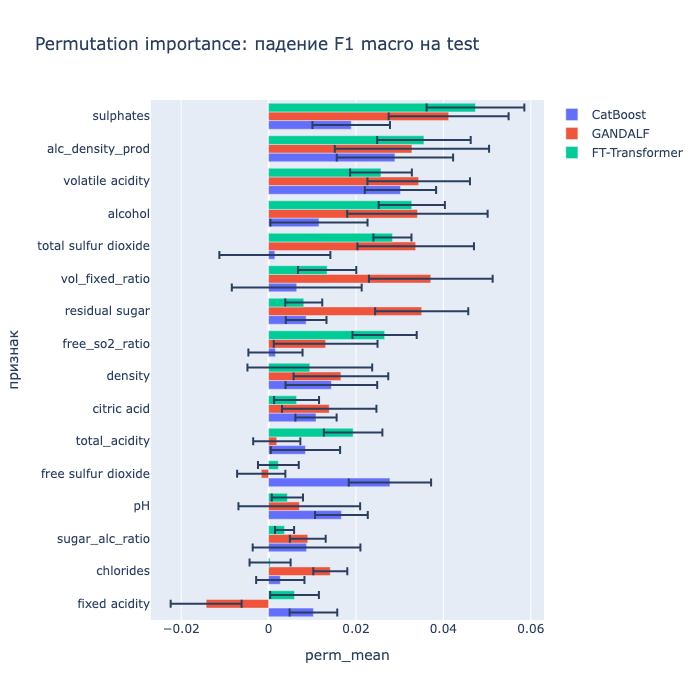

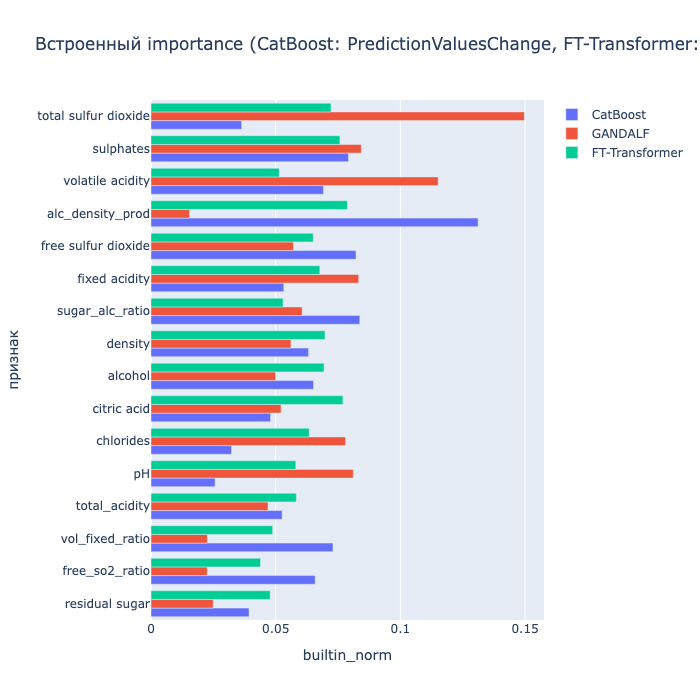

,Spearman
CatBoost: permutation vs встроенный,0.447059
FT-Transformer: permutation vs встроенный,0.291176
GANDALF: permutation vs встроенный,-0.038235
permutation: CatBoost vs FT-Transformer,0.117647
permutation: CatBoost vs GANDALF,0.050000
permutation: FT-Transformer vs GANDALF,0.591176


In [15]:
from itertools import combinations

from src.plots import plot_importance
from src.results import RUNS_DIR

imp = pd.concat(
    [
        pd.read_csv(RUNS_DIR / name / "importance.csv").assign(model=model)
        for model, name in FINAL.items()
    ]
)
imp["builtin_norm"] = imp["builtin"] / imp.groupby("model")["builtin"].transform("sum")
plot_importance(
    imp, "perm_mean", "perm_std", title="Permutation importance: падение F1 macro на test"
).show()
plot_importance(
    imp,
    "builtin_norm",
    title="Встроенный importance (CatBoost: PredictionValuesChange, FT-Transformer: attention, GANDALF: маски)",
).show()

perm = imp.pivot(index="feature", columns="model", values="perm_mean")
builtin = imp.pivot(index="feature", columns="model", values="builtin")
spearman = {
    f"{m}: permutation vs встроенный": perm[m].corr(builtin[m], method="spearman") for m in perm
}
for a, b in combinations(perm.columns, 2):
    spearman[f"permutation: {a} vs {b}"] = perm[a].corr(perm[b], method="spearman")
pd.Series(spearman, name="Spearman").to_frame()

> **Вывод:**

Общий для всех признак — `sulphates`: у обеих нейросетей он первый по permutation importance (0.0473 у `FT-Transformer`, 0.0412 у `GANDALF`), у `CatBoost` четвёртый (0.0189). Дальше модели расходятся: у `CatBoost` и `FT-Transformer` в топ-2 входит `alc_density_prod`, то есть алкоголь, а `CatBoost` сильнее всего опирается на `volatile acidity` (0.0302). Ранговая корреляция permutation importance между нейросетями 0.59, а между `CatBoost` и любой из них — 0.05–0.12. При этом std по перестановкам (0.002–0.018) сопоставим с разницей между соседними признаками, и у `GANDALF` `fixed acidity` даже получил отрицательное значение (−0.0143), так что надёжен только верх списка, а порядок в середине — шум 320 объектов test.

Встроенные механизмы с permutation совпадают слабо: Spearman 0.45 у `CatBoost`, 0.29 у `FT-Transformer` и −0.04 у `GANDALF`. Такое расхождение естественно: маски `GANDALF` показывают, какие признаки модель отбирает (лидер — `total sulfur dioxide`, 0.150 от суммы, хотя по permutation он только шестой), attention `FT-Transformer` в реализации `pytorch_tabular` — среднее по головам и блокам внимание токенов признаков к `[CLS]`, причём только на последнем батче forward (последние 64 объекта test; сама библиотека помечает этот расчёт как непроверенный). Веса у него почти равномерные (0.044–0.079 при 1/16 = 0.0625), так что к этой оценке я бы относился осторожно. Permutation же отвечает на другой вопрос — сколько `F1 macro` теряется без признака. По сути, для честного сравнения моделей годится только permutation importance, а встроенные механизмы описывают внутреннее устройство модели, а не вклад признака в качество.

## Проверка на объектах, созданных вручную

12 объектов построены от округлённых медиан train (`_BASE` в `src/data.py`); каждый тип меняет только перечисленные признаки. Внутри каждого рана они проходят тот же конвейер, что и обычные данные: `add_features` и собственная предобработка модели. Это не тестовая выборка, метрики на них не считаются. В датасете нет категориальных признаков, поэтому тип «неизвестная категория» не применим.

In [16]:
from src.data import _BASE, manual_objects

objs = manual_objects()
raw = list(_BASE)
lo, hi = train_df[raw].min(), train_df[raw].max()
out = (objs[raw] < lo) | (objs[raw] > hi)
table = objs[["id", "type", *raw]].copy()
table["вне диапазона train"] = out.apply(lambda r: ", ".join(r.index[r]), axis=1)
display(table)

,id,type,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,вне диапазона train
0,1,обычный,7.9,0.52,0.26,2.2,0.079,14.0,39.0,0.9968,3.3,0.62,10.1,
1,2,серия alcohol,7.9,0.52,0.26,2.2,0.079,14.0,39.0,0.9968,3.3,0.62,9.0,
2,3,серия alcohol,7.9,0.52,0.26,2.2,0.079,14.0,39.0,0.9968,3.3,0.62,11.0,
3,4,серия alcohol,7.9,0.52,0.26,2.2,0.079,14.0,39.0,0.9968,3.3,0.62,12.5,
4,5,серия alcohol,7.9,0.52,0.26,2.2,0.079,14.0,39.0,0.9968,3.3,0.62,14.0,
5,6,хорошее по признакам,7.9,0.35,0.40,2.2,0.079,14.0,39.0,0.9968,3.3,0.80,12.0,
6,7,плохое по признакам,7.9,0.90,0.05,2.2,0.079,14.0,39.0,0.9968,3.3,0.50,9.4,
7,8,"необычное, но возможное",7.9,1.20,0.26,2.2,0.079,14.0,39.0,0.9968,3.3,0.62,10.1,
8,9,вне train: alcohol,7.9,0.52,0.26,2.2,0.079,14.0,39.0,0.9968,3.3,0.62,16.0,alcohol
9,10,вне train: сладкое,7.9,0.52,0.26,25.0,0.079,14.0,39.0,1.0050,3.3,0.62,10.1,"residual sugar, density"


In [17]:
preds = None
for model, name in FINAL.items():
    m = pd.read_csv(RUNS_DIR / name / "manual.csv")
    m[f"{model}: класс"] = m["y_pred"]
    m[f"{model}: p"] = m[[f"prob_{c}" for c in CLASSES]].max(axis=1).round(3)
    m = m[["id", "type", f"{model}: класс", f"{model}: p"]]
    preds = m if preds is None else preds.merge(m, on=["id", "type"])
class_cols = [f"{model}: класс" for model in FINAL]
preds["модели согласны"] = preds[class_cols].nunique(axis=1) == 1
display(preds)

,id,type,CatBoost: класс,CatBoost: p,GANDALF: класс,GANDALF: p,FT-Transformer: класс,FT-Transformer: p,модели согласны
0,1,обычный,6,0.439,6,0.506,6,0.620,True
1,2,серия alcohol,5,0.439,5,0.718,6,0.504,False
2,3,серия alcohol,6,0.446,6,0.744,6,0.731,True
3,4,серия alcohol,6,0.324,6,0.754,6,0.647,True
4,5,серия alcohol,6,0.280,6,0.668,6,0.475,True
5,6,хорошее по признакам,7,0.381,6,0.496,7,0.490,False
6,7,плохое по признакам,4,0.355,5,0.745,5,0.798,False
7,8,"необычное, но возможное",4,0.344,5,0.619,5,0.616,False
8,9,вне train: alcohol,6,0.276,6,0.575,7,0.546,False
9,10,вне train: сладкое,6,0.350,6,0.482,6,0.548,True


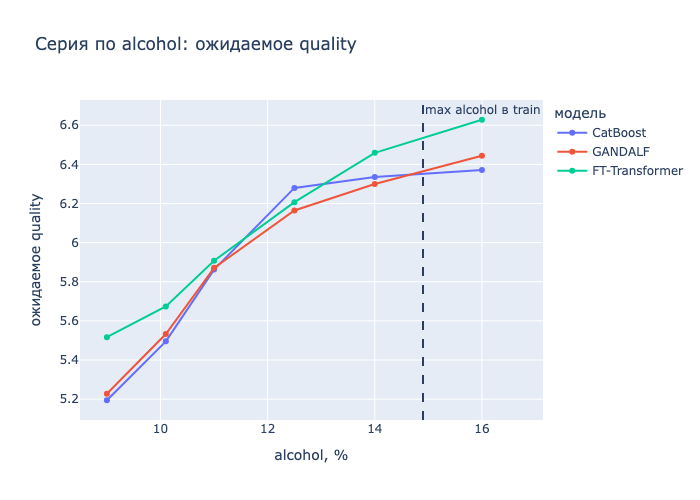

In [18]:
series_types = ["обычный", "серия alcohol", "вне train: alcohol"]
series = objs[objs["type"].isin(series_types)][["id", "alcohol"]].sort_values("alcohol")
rows = []
for model, name in FINAL.items():
    m = pd.read_csv(RUNS_DIR / name / "manual.csv").set_index("id").loc[series["id"]]
    expected = sum(m[f"prob_{c}"] * c for c in CLASSES)
    rows.append(
        pd.DataFrame(
            {
                "alcohol": series["alcohol"].values,
                "ожидаемое quality": expected.values,
                "модель": model,
            }
        )
    )
fig = px.line(
    pd.concat(rows),
    x="alcohol",
    y="ожидаемое quality",
    color="модель",
    markers=True,
    title="Серия по alcohol: ожидаемое quality",
    labels={"alcohol": "alcohol, %"},
)
fig.add_vline(
    x=train_df["alcohol"].max(),
    line_dash="dash",
    annotation_text="max alcohol в train",
)
fig.show()

> **Вывод:**

На обычном объекте (медианы train) все три модели дают класс `6`, и это правдоподобно: `5` и `6` вместе составляют большинство датасета. Уверенности при этом немного: у `GANDALF` `p=0.506`, у `CatBoost` `0.439`, у `FT-Transformer` `0.620`, то есть объект стоит почти на границе `5 / 6`. Серия по `alcohol` меняется так, как я и ожидал: ожидаемое quality монотонно растёт у всех моделей, у `CatBoost` с 5.194 при `alcohol=9.0` до 6.336 при `14.0`, у `GANDALF` с 5.228 до 6.299, у `FT-Transformer` с 5.517 до 6.459. «Хорошее» и «плохое» вино по признакам тоже уходят в правильные стороны (`7 / 6 / 7` и `4 / 5 / 5`), так что на уровне направлений модели выучили логику, совпадающую с importance: больше алкоголя и `sulphates`, меньше `volatile acidity` — выше оценка.

Модели согласны только на 6 объектах из 12, и расхождения устроены так же, как на test: `CatBoost` с `Balanced` весами смелее уходит в крайние классы (`4` для плохого вина и для `volatile acidity=1.2`), а нейросети держатся за `5` и `6`. Самое интересное — выход за `alcohol` train (максимум 14.9). При `alcohol=16.0` ожидаемое quality у `CatBoost` почти не сдвигается (6.336 → 6.371): деревья за пределами train просто повторяют последний лист. `FT-Transformer`, напротив, продолжает линию до 6.628 и переключается на класс `7` с `p=0.546` — по сути это экстраполяция, которой нечем подтвердиться. Категориальных признаков в датасете нет, поэтому объект с неизвестной категорией здесь не применим.

Меньше всего стоит доверять объектам 9–11, где признаки вне диапазона train (`alcohol`, сладкое вино с `residual sugar=25`, `chlorides=0.8` и `sulphates=2.5`), и противоречивому объекту 12. У последнего каждый признак по отдельности в диапазоне, но в train нет ни одного вина с `alcohol ≥ 13.5` и `volatile acidity ≥ 1.0` (0 из 1023). `CatBoost` честно показывает это самой низкой уверенностью из всех объектов (`p=0.208`), а нейросети уверенно ставят `6` (`0.751` у `GANDALF`, `0.607` у `FT-Transformer`). Если говорить по простому — высокая вероятность у нейросети вне области данных не означает надёжного ответа, и для таких объектов вероятности `CatBoost` выглядят более осторожными.

# II. Самостоятельное исследование архитектуры

## 2.1 Данные и экспериментальный протокол

- Тот же датасет `Red Wine Quality`, те же 16 признаков.
- Те же train / val / test = 1023 / 256 / 320, test как в ml-2 ЛР1.
- Те же метрики: основная — F1 macro, выбор модели и гиперпараметров только по val.
- Тот же baseline — CatBoost (`v10`) и те же 12 объектов, созданных вручную (`src/data.py: MANUAL_OBJECTS`).
- Всё обучение живёт в `src/train.py` и пишет `runs/vN/`, ноутбук только читает раны.

In [19]:
import json

from src.results import RUNS_DIR


def load_data_info(name):
    return json.loads((RUNS_DIR / name / "summary.json").read_text())["data"]


base_data = load_data_info("v10")
rows = []
for name, model in [("v10", "CatBoost"), ("v13", "TabLDM"), ("v14", "TabM")]:
    m = load_run(name).metrics
    data = load_data_info(name)
    same = (
        data["split_sha256"] == base_data["split_sha256"]
        and data["csv_sha256"] == base_data["csv_sha256"]
    )
    rows.append([name, model, m["n_train"], m["n_val"], m["n_test"], same])
pd.DataFrame(rows, columns=["ран", "модель", "n_train", "n_val", "n_test", "split совпадает с v10"])

,ран,модель,n_train,n_val,n_test,split совпадает с v10
0,v10,CatBoost,1023,256,320,True
1,v13,TabLDM,1023,256,320,True
2,v14,TabM,1023,256,320,True


> **Вывод:** протокол действительно общий: у `v10`, `v13` и `v14` совпадают и хэш CSV, и хэши индексов train / val / test (1023 / 256 / 320), поэтому разница в метриках дальше — это разница архитектур, а не разных экспериментов.

## 2.2 Подготовка данных и baseline

Финальный набор признаков — из раздела 1.2: 16 признаков, категориальных нет. Размеры выборок — в таблице 2.1. Baseline — `CatBoost` (`v10`), его метрики ниже.

Новые модели получают те же признаки, но представление признаков у моделей разное:

| модель | представление признаков |
| --- | --- |
| CatBoost | исходные значения |
| FT-Transformer / GANDALF | стандартизация `pytorch_tabular` по train (`normalize_continuous_features=True` по умолчанию) |
| TabLDM | исходные значения без масштабирования, своя предобработка внутри (клиппинг выбросов по z-score > 4, ансамбль вариантов нормализации, перестановки признаков и классов) |
| TabM | `QuantileTransformer` (normal) по train + кусочно-линейные эмбеддинги (`PiecewiseLinearEmbeddings`, 48 бинов по квантилям train) |

In [20]:
base = load_run("v10").metrics
base_names = {
    "F1 macro": "f1_macro",
    "balanced acc": "balanced_acc",
    "F1 weighted": "f1_weighted",
    "ROC AUC OvR": "roc_auc_ovr",
}
pd.DataFrame(
    {
        title: [base[f"{split}_{key}"] for split in ("val", "test")]
        for title, key in base_names.items()
    },
    index=["val", "test"],
)

,F1 macro,balanced acc,F1 weighted,ROC AUC OvR
val,0.292520,0.334266,0.527425,0.733936
test,0.329339,0.373781,0.550047,0.797835


> **Вывод:**

`Baseline` остается тем же `CatBoost` из части I: `F1 macro` 0.2925 на val и 0.3293 на test, `balanced accuracy` 0.3343 и 0.3738. Test у него выше val почти на 0.04 — при 256 объектах val, где классов `3` и `8` всего 2 и 3 вина, это скорее шум разбиения, чем особенность модели, поэтому сравнивать новые модели с ним стоит по обеим выборкам, а не по одной цифре.

Набор признаков для новых моделей я не менял, поменялось только их представление. `TabLDM` получает сырые значения, так как нормализация и клиппинг выбросов у него встроены и являются частью того, на чем модель предобучалась. `TabM`, наоборот, без хорошего кодирования чисел теряет главное преимущество, поэтому для него признаки проходят `QuantileTransformer` и кусочно-линейные эмбеддинги — и то, и другое обучается только на train.

## 2.3 Новые архитектуры: TabLDM и TabM

### Выбор реализации

| | TabLDM | TabM |
| --- | --- | --- |
| источник | Xiaomi, 2026, arXiv 2609.03880; git `xiaomi-research/xiaomi-tabldm`, не на PyPI | Yandex, ICLR 2025; PyPI `tabm` + `rtdl_num_embeddings` |
| версия | коммит `03cfbb9`; веса на HF `occams/Xiaomi-TabLDM`, `checkpoints/clf_default.ckpt`, ревизия `712e563` (закреплена в `src/train.py`) | `tabm` 0.0.3, `rtdl_num_embeddings` 0.0.12 |
| последнее обновление | 2026-10-26 (коммит `03cfbb9`) | релиз `tabm` 0.0.3 на PyPI — 2025-08-14; репозиторий `yandex-research/tabm` — 2025-11-10 |
| Python | пакет заявляет 3.10–3.12, на 3.13 работает (проверено в этой лабе) | `>=3.9`, на 3.13 работает |
| зависимости | torch, scikit-learn, einops, huggingface-hub, scipy, pandas | только torch |
| API | sklearn: `fit` / `predict_proba`, `fit` веса не обновляет | `torch.nn.Module` (`TabM.make`), цикл обучения свой (`src/train.py: fit_tabm`) |
| документация | README + tutorials | README + пример-ноутбук в репозитории авторов |
| устройство | авторы заявляют CUDA/CPU, здесь MPS (FlashAttention вне CUDA недоступен, вместо него PyTorch SDPA) | MPS |

### Идея архитектур

- Идея `TabLDM`: это tabular foundation model в духе `TabPFN` — трансформер, который не обучается на наших данных вообще. Его заранее предобучили на огромном количестве синтетических задач, сгенерированных из структурных причинных моделей (SCM), и по сути он выучил не конкретную зависимость, а сам процесс «как по размеченной таблице предсказать новую строку». Поэтому `fit` здесь веса не трогает: train просто становится контекстом, и предсказание для объекта test получается за один forward pass, где attention работает и между признаками внутри строки, и между строкой test и строками контекста (отсюда сложность `O(n^2 + nm^2)` из README). В отличие от `MLP`, который подгоняет свои веса под 1023 объекта и легко на них переобучается, `TabLDM` опирается на prior, выученный на синтетике, — это in-context learning, а не обучение. Поверх этого библиотека строит ансамбль: 16 прогонов с разными перестановками признаков и классов и разными вариантами нормализации, а в режиме `enhance_candidates` еще и подбирает веса 64 кандидатов по 5-fold OOF на train.
- Идея `TabM`: проблема обычного `MLP` на таблицах в том, что одна сеть нестабильна и заметно уступает бустингу, а честный ансамбль из десятков `MLP` дорого обучать. `TabM` делает ансамбль из `k=32` `MLP` внутри одной сети: линейные слои общие для всех членов ансамбля, а различаются они только дешевыми поэлементными масштабирующими векторами (идея `BatchEnsemble`). Все 32 «головы» обучаются одновременно, каждая со своей `CrossEntropy`, а предсказание — среднее их вероятностей, поэтому модель получает выигрыш ансамбля почти по цене одной сети (594 624 параметров в нашей конфигурации). Вторая важная часть — кодирование чисел: каждый признак не подается одним скаляром, а раскладывается кусочно-линейно по 48 бинам, построенным по квантилям train (`PiecewiseLinearEmbeddings`), что дает сети более «деревянное» представление порогов.

Замен не было: обе библиотеки установились и работают на MPS.

In [21]:
# у TabLDM «обучение» — fit: построение контекста, весов он не обновляет, эпох нет
rows = {}
for model, name in [("CatBoost", "v10"), ("TabLDM", "v13"), ("TabM", "v14")]:
    m = load_run(name).metrics
    rows[f"{model} ({name})"] = {
        "val F1 macro": m["val_f1_macro"],
        "val balanced acc": m["val_balanced_acc"],
        "val ROC AUC": m["val_roc_auc_ovr"],
        "test F1 macro": m["test_f1_macro"],
        "время обучения, с": m["train_time_sec"],
        "inference test, с": m["inference_time_sec"],
        "параметров": m.get("n_params"),
        "эпох (лучшая)": m.get("best_epoch", "—"),
    }
pd.DataFrame(rows).T

,val F1 macro,val balanced acc,val ROC AUC,test F1 macro,"время обучения, с","inference test, с",параметров,эпох (лучшая)
CatBoost (v10),0.29252,0.334266,0.733936,0.329339,2.130627,0.000212,None,—
TabLDM (v13),0.393334,0.404774,0.86486,0.32465,96.345776,24.807853,70075010,—
TabM (v14),0.288606,0.294284,0.815068,0.300867,3.764777,0.017469,594624.0,10.0


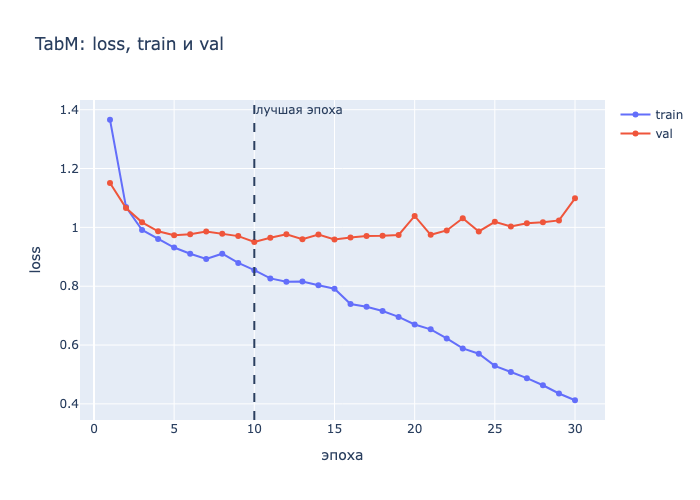

In [22]:
tabm = load_run("v14")
fig = plot_curves(tabm.history, "loss", title="TabM: loss, train и val")
fig.add_vline(x=tabm.metrics["best_epoch"], line_dash="dash", annotation_text="лучшая эпоха")
fig.update_layout(xaxis_title="эпоха", yaxis_title="loss")
fig.show()

> **Вывод:**

`TabLDM` без единого шага обучения сразу стал лучшим по val: `F1 macro` 0.3933 против 0.2925 у `CatBoost`, то есть +0.10 — это в 25 раз больше разброса ±0.004, который я видел между перезапусками одной конфигурации в части I. Однако на test картина другая: 0.3246 против 0.3293 у `CatBoost`. При этом `F1 weighted` (0.6336 против 0.5500) и `ROC AUC` (0.8470 против 0.7978) у `TabLDM` на test заметно выше. Разгадка в редких классах: на частых классах `5`–`7` `TabLDM` лучше бустинга на 0.06–0.14 по F1, но класс `4` на test не угадывает ни разу (у `CatBoost` с весами классов 0.323), а классы `4` и `8` предсказывает по одному разу из 320. Если говорить по простому — вероятности он ранжирует лучше всех, но `argmax` тянет его к частым классам. Вообще, результат меня удивил: я ожидал, что на 1023 объектах foundation-модель будет примерно на уровне бустинга, а не на 0.10 выше по val.

`TabM` в базовой конфигурации оказался на уровне нейросетей части I: 0.2886 на val и 0.3009 на test, обучение заняло всего 3.8 с. По кривой видно быстрое переобучение — лучшая эпоха 10 из 30, к 30-й эпохе val loss вырос с 0.9502 до 1.0986, а train loss за то же время упал с 0.8547 до 0.4123. Для сети с 594 624 параметрами на 1023 объектах это ожидаемо, так что на этапе 7 первым делом стоит подобрать `lr` и регуляризацию. Цена `TabLDM` тоже видна в таблице: 96 с на `fit` и 24.8 с на inference test против 0.0002 с у `CatBoost`.

## 2.4 Исследование TabLDM и TabM

Базовые конфигурации: `v13` (TabLDM «из коробки») и `v14` (TabM «из коробки», параметры авторов: lr 2e-3, wd 3e-4). Дальше по одной гипотезе за итерацию (H1–H9: lr / wd, `k`, ширина и глубина, dropout, кодирование числовых признаков у TabM; `n_estimators`, `enhance_candidates`, поправка на приоры, `norm_methods` у TabLDM). Выбор конфигурации идет только по val F1 macro, test показан справочно. Один прогон TabM шумит примерно на ±0.03, поэтому H3 и H4 проверены на seeds 42 / 43 / 44, а финальные конфигурации — на seeds 42–46. Seed меняет и инициализацию, и разбиение train/val (`load_splits(seed)`), test зафиксирован. Набор данных и признаки не меняются: результаты сравнимы со всеми ранами.

In [23]:
from src.results import load_run

rows = []
for model, name in [("TabLDM", "v13"), ("TabM", "v14")]:
    r = load_run(name)
    c = r.config
    if model == "TabLDM":
        params = f"n_estimators {c['tabldm_n_estimators']}, enhance {c['tabldm_enhance']}"
        epochs, best_epoch = "—", "—"
    else:
        params = (
            f"k {c['tabm_k']}, {c['tabm_d_block']} × {c['tabm_n_blocks']}, "
            f"dropout {c['tabm_dropout']:g}, lr {c['lr']:g}, wd {c['weight_decay']:g}"
        )
        epochs = len(r.history)
        best_epoch = int(r.history.loc[r.history["val_loss"].idxmin(), "epoch"])
    rows.append(
        [
            model,
            name,
            params,
            epochs,
            best_epoch,
            round(r.metrics["val_f1_macro"], 4),
            round(r.metrics["train_time_sec"], 2),
            round(r.metrics["inference_time_sec"], 3),
        ]
    )
pd.DataFrame(
    rows,
    columns=[
        "модель",
        "ран",
        "параметры",
        "эпох обучено",
        "лучшая эпоха",
        "val F1 macro",
        "train_time, с",
        "inference_time, с",
    ],
)

,модель,ран,параметры,эпох обучено,лучшая эпоха,val F1 macro,"train_time, с","inference_time, с"
0,TabLDM,v13,"n_estimators 16, enhance True",—,—,0.3933,96.35,24.808
1,TabM,v14,"k 32, 512 × 2, dropout 0.1, lr 0.002, wd 0.0003",30,10,0.2886,3.76,0.017


In [24]:
def fmt(values):
    """Одно значение или mean ± std по seeds (std с ddof=1)."""
    s = pd.Series(values)
    return f"{s.iloc[0]:.4f}" if len(s) == 1 else f"{s.mean():.4f} ± {s.std():.4f}"


def tabm_lr(r):
    return f"lr {r.config['lr']:g}, wd {r.config['weight_decay']:g}"


def tabm_shape(r):
    return f"{r.config['tabm_d_block']} × {r.config['tabm_n_blocks']}, 3 seeds"


def tabldm_n(r):
    enhance = "вкл" if r.config["tabldm_enhance"] else "выкл"
    return f"n_estimators {r.config['tabldm_n_estimators']}, enhance {enhance}"


# (модель, гипотеза, раны, описание значения по первому рану, вердикт)
experiments = [
    ("TabM", "H1: lr и wd из Optuna", ["v15"], lambda r: tabm_lr(r) + " (Optuna)", "подтверждена"),
    (
        "TabM",
        "H2: рост до k ≈ 32, затем плато",
        ["v19"],
        lambda r: "k 1, " + tabm_lr(r),
        "рост от k 1 подтвержден",
    ),
    (
        "TabM",
        "H2: рост до k ≈ 32, затем плато",
        ["v17"],
        lambda r: "k 8, " + tabm_lr(r) + " (lr от k 32)",
        "рост от k 1 подтвержден",
    ),
    (
        "TabM",
        "H2: рост до k ≈ 32, затем плато",
        ["v20"],
        lambda r: "k 64, " + tabm_lr(r),
        "32 vs 64 в пределах шума",
    ),
    (
        "TabM",
        "H3: узкая сеть не хуже, меньше переобучения",
        ["v26", "v34", "v43"],
        tabm_shape,
        "не хуже — да, меньше переобучения — нет",
    ),
    (
        "TabM",
        "H3: узкая сеть не хуже, меньше переобучения",
        ["v15", "v36", "v45"],
        tabm_shape,
        "не хуже — да, меньше переобучения — нет",
    ),
    (
        "TabM",
        "H4: dropout 0.3 вместо 0.1 (256 × 3)",
        ["v47", "v48", "v49"],
        lambda r: f"dropout {r.config['tabm_dropout']:g}, 3 seeds",
        "в пределах шума, переобучение не уменьшилось",
    ),
    (
        "TabLDM",
        "H5: плато к 8–16, inference растет линейно",
        ["v50"],
        tabldm_n,
        "плато уже с n = 1",
    ),
    (
        "TabLDM",
        "H5: плато к 8–16, inference растет линейно",
        ["v51"],
        tabldm_n,
        "плато уже с n = 1",
    ),
    (
        "TabLDM",
        "H5: плато к 8–16, inference растет линейно",
        ["v52"],
        tabldm_n,
        "плато уже с n = 1",
    ),
    (
        "TabLDM",
        "H5: плато к 8–16, inference растет линейно",
        ["v53"],
        tabldm_n,
        "плато уже с n = 1",
    ),
    (
        "TabLDM",
        "H5: плато к 8–16, inference растет линейно",
        ["v54"],
        tabldm_n,
        "плато уже с n = 1",
    ),
    (
        "TabLDM",
        "H6: enhance выкл быстрее, F1 ниже",
        ["v55"],
        tabldm_n,
        "F1 не упал, fit и inference быстрее; финал — v55",
    ),
    (
        "TabLDM",
        "H6: enhance выкл быстрее, F1 ниже",
        ["v56"],
        tabldm_n,
        "F1 не упал, fit и inference быстрее",
    ),
    (
        "TabLDM",
        "H6: enhance выкл быстрее, F1 ниже",
        ["v57"],
        tabldm_n,
        "F1 не упал, fit и inference быстрее",
    ),
    (
        "TabLDM",
        "H7: поправка на приоры классов",
        ["v58"],
        lambda r: f"alpha {r.metrics['tabldm_alpha']:g}",
        "не подтверждена: лучший alpha 0",
    ),
    (
        "TabM",
        "H8: без эмбеддингов (только QT) хуже QT + PLE",
        [f"v{i}" for i in range(79, 84)],
        lambda r: "QT + PLE, " + tabm_lr(r) + ", 5 seeds",
        "референс (финальный TabM)",
    ),
    (
        "TabM",
        "H8: без эмбеддингов (только QT) хуже QT + PLE",
        [f"v{i}" for i in range(104, 109)],
        lambda r: "только QT, " + tabm_lr(r) + " (Optuna), 5 seeds",
        "подтверждена, Δ val −0.039",
    ),
    (
        "TabLDM",
        "H9: norm_methods, разница ≤ 0.02",
        [f"v{i}" for i in range(74, 79)],
        lambda r: "norm_methods none,power (дефолт), 5 seeds",
        "референс (финальный TabLDM)",
    ),
    (
        "TabLDM",
        "H9: norm_methods, разница ≤ 0.02",
        [f"v{i}" for i in range(84, 89)],
        lambda r: f"norm_methods {r.config['tabldm_norm_methods']}, 5 seeds",
        "в пределах шума",
    ),
    (
        "TabLDM",
        "H9: norm_methods, разница ≤ 0.02",
        [f"v{i}" for i in range(89, 94)],
        lambda r: f"norm_methods {r.config['tabldm_norm_methods']}, 5 seeds",
        "в пределах шума",
    ),
    (
        "TabLDM",
        "H9: norm_methods, разница ≤ 0.02",
        [f"v{i}" for i in range(94, 99)],
        lambda r: f"norm_methods {r.config['tabldm_norm_methods']}, 5 seeds",
        "в пределах шума",
    ),
    (
        "TabLDM",
        "H9: norm_methods, разница ≤ 0.02",
        [f"v{i}" for i in range(99, 104)],
        lambda r: f"norm_methods {r.config['tabldm_norm_methods']}, 5 seeds",
        "в пределах шума",
    ),
]
rows = []
for model, hypothesis, names, value, verdict in experiments:
    runs = [load_run(n) for n in names]
    rows.append(
        [
            model,
            ", ".join(names),
            hypothesis,
            value(runs[0]),
            fmt([r.metrics["val_f1_macro"] for r in runs]),
            fmt([r.metrics["test_f1_macro"] for r in runs]),
            verdict,
        ]
    )
pd.DataFrame(
    rows,
    columns=[
        "модель",
        "ран",
        "гипотеза",
        "значение",
        "val F1 macro",
        "test F1 macro (справочно)",
        "вывод",
    ],
)

,модель,ран,гипотеза,значение,val F1 macro,test F1 macro (справочно),вывод
0,TabM,v15,H1: lr и wd из Optuna,"lr 0.009, wd 3e-05 (Optuna)",0.3542,0.3188,подтверждена
1,TabM,v19,"H2: рост до k ≈ 32, затем плато","k 1, lr 0.01, wd 1e-05",0.3260,0.2428,рост от k 1 подтвержден
2,TabM,v17,"H2: рост до k ≈ 32, затем плато","k 8, lr 0.009, wd 3e-05 (lr от k 32)",0.2934,0.2624,рост от k 1 подтвержден
3,TabM,v20,"H2: рост до k ≈ 32, затем плато","k 64, lr 0.007, wd 0.0004",0.3811,0.3248,32 vs 64 в пределах шума
4,TabM,"v26, v34, v43","H3: узкая сеть не хуже, меньше переобучения","256 × 3, 3 seeds",0.3632 ± 0.0522,0.3348 ± 0.0153,"не хуже — да, меньше переобучения — нет"
5,TabM,"v15, v36, v45","H3: узкая сеть не хуже, меньше переобучения","512 × 2, 3 seeds",0.3080 ± 0.0440,0.3049 ± 0.0171,"не хуже — да, меньше переобучения — нет"
6,TabM,"v47, v48, v49",H4: dropout 0.3 вместо 0.1 (256 × 3),"dropout 0.3, 3 seeds",0.3346 ± 0.0155,0.3292 ± 0.0130,"в пределах шума, переобучение не уменьшилось"
7,TabLDM,v50,"H5: плато к 8–16, inference растет линейно","n_estimators 1, enhance вкл",0.3906,0.3246,плато уже с n = 1
8,TabLDM,v51,"H5: плато к 8–16, inference растет линейно","n_estimators 4, enhance вкл",0.3906,0.3259,плато уже с n = 1
9,TabLDM,v52,"H5: плато к 8–16, inference растет линейно","n_estimators 8, enhance вкл",0.4039,0.3246,плато уже с n = 1


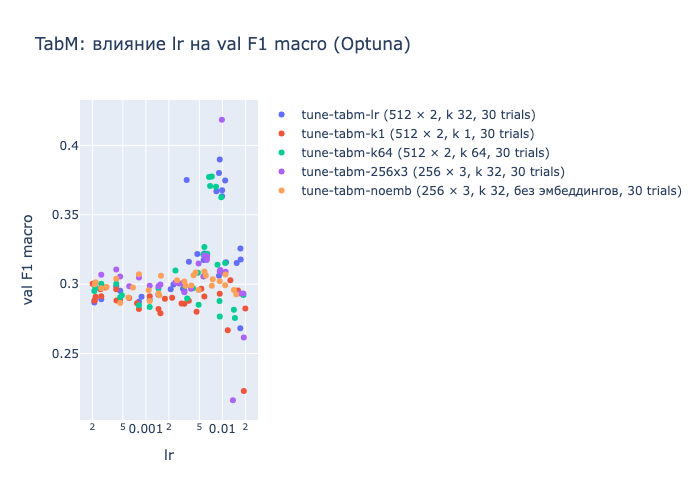

In [25]:
import optuna
import plotly.graph_objects as go

optuna.logging.set_verbosity(optuna.logging.WARNING)

studies = [
    ("tune-tabm-lr", "512 × 2, k 32"),
    ("tune-tabm-k1", "512 × 2, k 1"),
    ("tune-tabm-k64", "512 × 2, k 64"),
    ("tune-tabm-256x3", "256 × 3, k 32"),
    ("tune-tabm-noemb", "256 × 3, k 32, без эмбеддингов"),
]
fig = go.Figure()
for name, config in studies:
    study = optuna.load_study(study_name=name, storage=f"sqlite:///runs/tune/{name}.db")
    trials = [t for t in study.trials if t.state == optuna.trial.TrialState.COMPLETE]
    fig.add_trace(
        go.Scatter(
            x=[t.params["lr"] for t in trials],
            y=[t.value for t in trials],
            mode="markers",
            name=f"{name} ({config}, {len(trials)} trials)",
        )
    )
fig.update_layout(
    title="TabM: влияние lr на val F1 macro (Optuna)",
    xaxis_title="lr",
    yaxis_title="val F1 macro",
    xaxis_type="log",
)
fig.show()

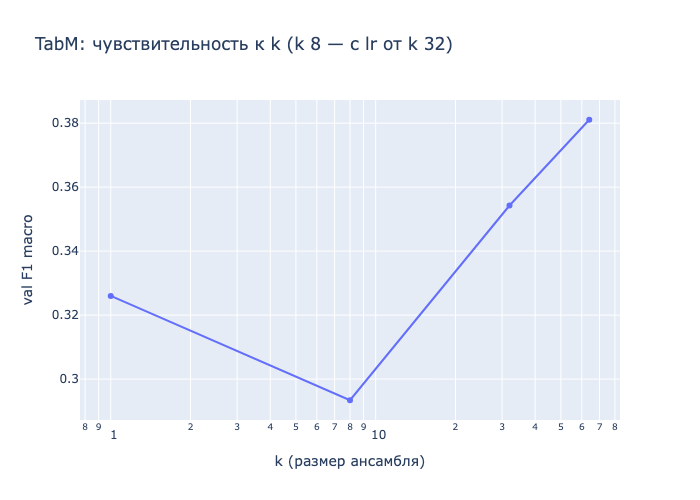

In [26]:
k_runs = [load_run(n) for n in ["v19", "v17", "v15", "v20"]]
ks = [r.config["tabm_k"] for r in k_runs]
notes = [
    f"lr {r.config['lr']:g}, wd {r.config['weight_decay']:g}"
    + (" (lr от k 32)" if r.config["tabm_k"] == 8 else "")
    for r in k_runs
]
fig = go.Figure(
    go.Scatter(
        x=ks,
        y=[r.metrics["val_f1_macro"] for r in k_runs],
        mode="lines+markers",
        text=notes,
        hovertemplate="k %{x}<br>val F1 macro %{y:.4f}<br>%{text}<extra></extra>",
    )
)
fig.update_layout(
    title="TabM: чувствительность к k (k 8 — с lr от k 32)",
    xaxis_title="k (размер ансамбля)",
    yaxis_title="val F1 macro",
    xaxis_type="log",
)
fig.show()

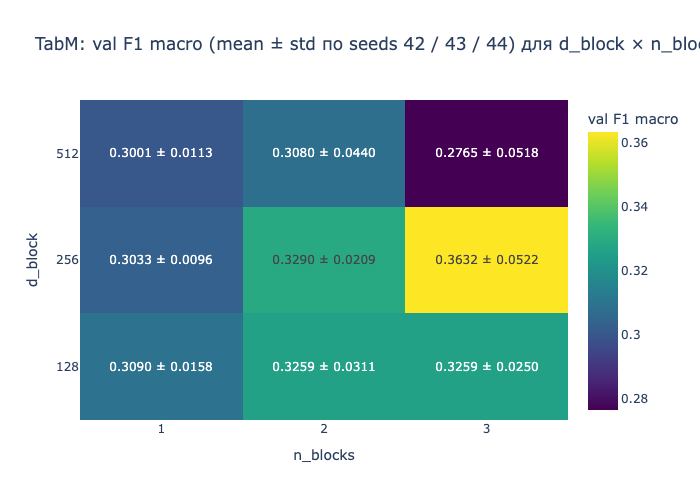

In [27]:
grid_names = ["v15"] + [f"v{i}" for i in range(21, 47)]
grid = pd.DataFrame(
    [
        {
            "d_block": r.config["tabm_d_block"],
            "n_blocks": r.config["tabm_n_blocks"],
            "seed": r.config["seed"],
            "val_f1": r.metrics["val_f1_macro"],
        }
        for r in map(load_run, grid_names)
    ]
)
assert set(grid["seed"]) == {42, 43, 44}
stats = grid.groupby(["d_block", "n_blocks"])["val_f1"].agg(["mean", "std", "count"])
assert (stats["count"] == 3).all()
mean = stats["mean"].unstack("n_blocks")
std = stats["std"].unstack("n_blocks")
fig = go.Figure(
    go.Heatmap(
        z=mean.values,
        x=[str(n) for n in mean.columns],
        y=[str(d) for d in mean.index],
        text=(mean.map("{:.4f}".format) + " ± " + std.map("{:.4f}".format)).values,
        texttemplate="%{text}",
        colorscale="Viridis",
        colorbar_title="val F1 macro",
    )
)
fig.update_layout(
    title="TabM: val F1 macro (mean ± std по seeds 42 / 43 / 44) для d_block × n_blocks",
    xaxis_title="n_blocks",
    yaxis_title="d_block",
)
fig.show()

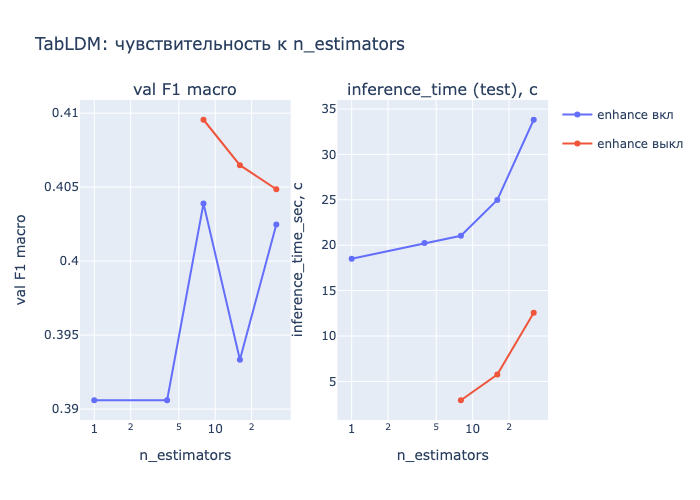

In [28]:
from plotly.subplots import make_subplots

ldm_runs = [load_run(f"v{i}") for i in range(50, 58)]
fig = make_subplots(
    rows=1,
    cols=2,
    subplot_titles=("val F1 macro", "inference_time (test), с"),
)
for enhance, label in [(True, "enhance вкл"), (False, "enhance выкл")]:
    group = [r for r in ldm_runs if r.config["tabldm_enhance"] == enhance]
    n = [r.config["tabldm_n_estimators"] for r in group]
    for col, metric in [(1, "val_f1_macro"), (2, "inference_time_sec")]:
        fig.add_trace(
            go.Scatter(
                x=n,
                y=[r.metrics[metric] for r in group],
                mode="lines+markers",
                name=label,
                legendgroup=label,
                showlegend=col == 1,
                line_color="#636EFA" if enhance else "#EF553B",
            ),
            row=1,
            col=col,
        )
fig.update_xaxes(title_text="n_estimators", type="log")
fig.update_yaxes(title_text="val F1 macro", row=1, col=1)
fig.update_yaxes(title_text="inference_time_sec, с", row=1, col=2)
fig.update_layout(title="TabLDM: чувствительность к n_estimators")
fig.show()

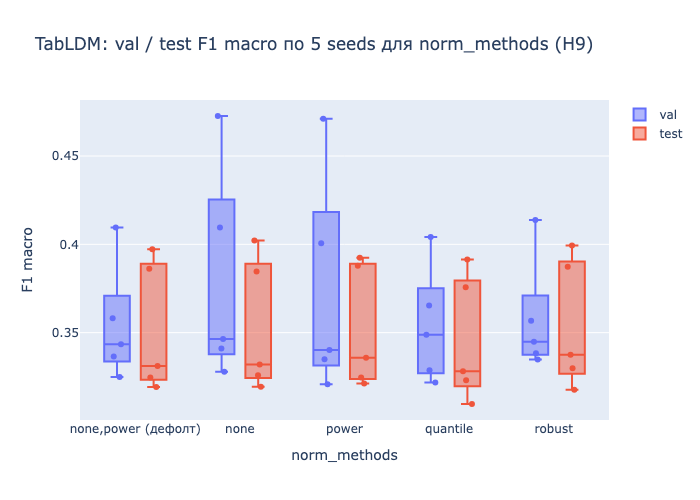

In [29]:
variants = [
    ("none,power (дефолт)", [f"v{i}" for i in range(74, 79)]),
    ("none", [f"v{i}" for i in range(84, 89)]),
    ("power", [f"v{i}" for i in range(89, 94)]),
    ("quantile", [f"v{i}" for i in range(94, 99)]),
    ("robust", [f"v{i}" for i in range(99, 104)]),
]
norm_runs = {label: [load_run(n) for n in names] for label, names in variants}
for label, runs in norm_runs.items():
    assert [r.config["seed"] for r in runs] == [42, 43, 44, 45, 46], label

fig = go.Figure()
for split in ["val", "test"]:
    fig.add_trace(
        go.Box(
            x=[label for label, runs in norm_runs.items() for _ in runs],
            y=[r.metrics[f"{split}_f1_macro"] for runs in norm_runs.values() for r in runs],
            name=split,
            boxpoints="all",
            jitter=0.4,
            pointpos=0,
        )
    )
fig.update_layout(
    title="TabLDM: val / test F1 macro по 5 seeds для norm_methods (H9)",
    xaxis_title="norm_methods",
    yaxis_title="F1 macro",
    boxmode="group",
)
fig.show()

> **Вывод:**

У `TabM` главным рычагом снова оказался `lr`, как и у нейросетей части I: при параметрах авторов (`lr` 2e-3) `v14` дал val `F1 macro` 0.2886, а после Optuna (`lr` 9e-3, `wd` 3e-5) `v15` вырос до 0.3542. Пройдясь по чек-листу условия, слабый `baseline` объясняется именно этим: эпох хватало (`v14` остановился на 30-й эпохе по early stopping, лучшая — 10-я, дальше val loss в целом растет до 1.0986), числа проходят `QuantileTransformer`, обученный на train, и кусочно-линейные эмбеддинги, категориальных признаков нет, а test отделен заранее и одинаков для всех моделей. Ансамбль внутри `TabM` работает: при своих `lr` / `wd` переход от `k` 1 к `k` 64 дал 0.3260 → 0.3811. Однако разница между `k` 32 и 64, как и между большинством форм сети, сравнима с шумом: у лучшей формы 256 × 3 на трех seeds 0.3632 ± 0.0522, а у 512 × 2 0.3080 ± 0.0440. Устойчиво видно только то, что 512 × 3 хуже всех (0.2765). Dropout 0.3 вместо 0.1 сделал модель стабильнее (std 0.0155 против 0.0522), но не точнее, и переобучение после лучшей эпохи не убрал. Кусочно-линейные эмбеддинги (`PLE`) оказались нужны: без них, только на `QuantileTransformer` и со своими `lr` / `wd` из Optuna, `TabM` на 5 seeds дал val 0.3028 ± 0.0269 против 0.3421 ± 0.0528 и проиграл на 4 seeds из 5. По сути, `PLE` заранее режет каждый признак на отрезки по квантилям train, как пороги деревьев, а MLP без них на 1023 объектах строит эти пороги хуже: min val loss выше на всех seeds (0.9313 против 0.8795 в среднем).

У `TabLDM` обучать нечего, поэтому исследовались настройки ансамбля и решающее правило. `n_estimators` почти ни на что не влияет: при `enhance_candidates` он задает только главную группу кандидатов, а остальные группы и смесь по `NNLS` (при `n_estimators` 32 — 80 кандидатов) остаются, и val держится в пределах 0.3906–0.4039. Зато отключение `enhance_candidates` дало val 0.4096 при inference 2.9 с вместо 24.8 с у `v13`, а fit сократился с 96.3 с до 0.74 с. Вообще, этот результат меня удивил: я ожидал, что ради скорости придется пожертвовать хотя бы 0.01 `F1 macro`, а на 1023 объектах train смесь кандидатов по весам `NNLS` оказалась не точнее простого усреднения. Поправка вероятностей редких классов (`H7`) не подтвердилась: по val выбрана `alpha` 0, любая поправка снижала val на 0.013–0.104, потому что выигрыш на 1–2 объектах классов `3` / `4` / `8` не окупает ошибок на классах `5`–`7`. Нормализация числовых признаков (`norm_methods`, `H9`) тоже почти ничего не меняет: по test все варианты лежат в 0.3456–0.3543 против 0.3517 у дефолта [none, power]. По среднему val вариант none выше дефолта на 0.025 (0.3795 против 0.3545), но этот выигрыш держится на одном seed 45 (0.4726 против 0.3581), поэтому дефолт я оставил: `TabLDM` сам стандартизирует признаки, и монотонное преобразование поверх ему не важно.

Если говорить по простому - обе модели упираются не в гиперпараметры, а в 13 объектов редких классов на val, из-за которых одиночный ран шумит на ±0.03. Данные по решению этапа мы не меняли, но дальше стоило бы попробовать объединить редкие классы `3` и `8` с соседними `4` и `7`, перейти к порядковой постановке (оценка вина упорядочена) или добавить белое вино из того же набора UCI как источник дополнительных объектов редких оценок.

### Лучшие конфигурации на 5 seeds

In [30]:
FINALS = {
    "CatBoost": range(59, 64),
    "GANDALF": range(64, 69),
    "FT-Transformer": range(69, 74),
    "TabLDM": range(74, 79),
    "TabM": range(79, 84),
}
final_runs = {m: [load_run(f"v{i}") for i in ids] for m, ids in FINALS.items()}
for m, runs in final_runs.items():
    assert [r.config["seed"] for r in runs] == [42, 43, 44, 45, 46], m


def mean_std(runs, metric):
    s = pd.Series([r.metrics[metric] for r in runs])
    return f"{s.mean():.4f} ± {s.std():.4f}"


def mean_3g(runs, metric):
    return f"{pd.Series([r.metrics[metric] for r in runs]).mean():.3g}"


pd.DataFrame(
    [
        [
            m,
            mean_std(runs, "val_f1_macro"),
            mean_std(runs, "test_f1_macro"),
            mean_std(runs, "test_balanced_acc"),
            mean_3g(runs, "train_time_sec"),
            mean_3g(runs, "inference_time_sec"),
        ]
        for m, runs in final_runs.items()
    ],
    columns=[
        "модель",
        "val F1 macro",
        "test F1 macro",
        "test balanced acc",
        "train_time, с (среднее)",
        "inference_time, с (среднее)",
    ],
)

,модель,val F1 macro,test F1 macro,test balanced acc,"train_time, с (среднее)","inference_time, с (среднее)"
0,CatBoost,0.3191 ± 0.0541,0.3469 ± 0.0382,0.4084 ± 0.0558,2.22,0.000369
1,GANDALF,0.2848 ± 0.0192,0.2953 ± 0.0105,0.2868 ± 0.0075,4.98,0.00568
2,FT-Transformer,0.2713 ± 0.0620,0.2624 ± 0.0472,0.2729 ± 0.0415,11.6,0.0606
3,TabLDM,0.3545 ± 0.0330,0.3517 ± 0.0370,0.3356 ± 0.0265,0.898,3.26
4,TabM,0.3421 ± 0.0528,0.3294 ± 0.0182,0.3268 ± 0.0136,4.36,0.0142


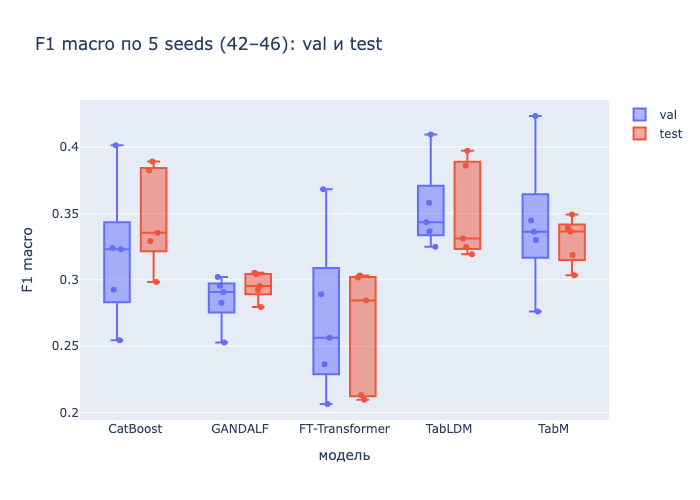

In [31]:
fig = go.Figure()
for split in ["val", "test"]:
    fig.add_trace(
        go.Box(
            x=[m for m, runs in final_runs.items() for _ in runs],
            y=[r.metrics[f"{split}_f1_macro"] for runs in final_runs.values() for r in runs],
            name=split,
            boxpoints="all",
            jitter=0.4,
            pointpos=0,
        )
    )
fig.update_layout(
    title="F1 macro по 5 seeds (42–46): val и test",
    xaxis_title="модель",
    yaxis_title="F1 macro",
    boxmode="group",
)
fig.show()

> **Вывод:**

Повтор на 5 seeds заметно отрезвляет: у `TabLDM` и `TabM` seed 42, на котором шел весь подбор, оказался лучшим из пяти (val 0.4096 и 0.4235), а средние — 0.3545 ± 0.0330 и 0.3421 ± 0.0528. Это не ошибка, а следствие протокола: seed меняет и разбиение train / val, поэтому выбор конфигураций по одному seed частично подогнан под конкретные 256 объектов val. По test новые модели действительно сильнее нейросетей части I: `TabLDM` 0.3517 ± 0.0370 и `TabM` 0.3294 ± 0.0182 против 0.2953 ± 0.0105 у `GANDALF` и 0.2624 ± 0.0472 у `FT-Transformer`, и этот разрыв больше разброса. При этом `CatBoost` держится на уровне лидера (0.3469 ± 0.0382, разница с `TabLDM` 0.005 при std около 0.037), а по test `balanced accuracy` он вообще лучший — 0.4084 ± 0.0558, во многом за счет `auto_class_weights='Balanced'`.

По времени модели устроены противоположно. `TabLDM` почти не обучается (0.898 с на fit), но inference на 320 объектах занимает 3.26 с, в 230 раз дольше, чем у `TabM` (0.0142 с), у которого обучение 4.36 с. В целом, на таком маленьком датасете я отдаю свое предпочтение `TabLDM`: лучший средний test `F1 macro` без подбора весов, а цена в 3 секунды inference здесь несущественна. Но универсального лидера нет: если важнее находить редкие оценки, а не `F1 macro`, `CatBoost` с весами классов выглядит не хуже, а работает на порядки быстрее.

## 2.5 Итоговое сравнение

TODO (этап 8)

### Test

> **Вывод:** TODO

### Анализ ошибок

> **Вывод:** TODO

### Интерпретация

> **Вывод:** TODO

## Повтор проверки на ручных объектах

TODO (этап 8: все модели на тех же объектах)

> **Вывод:** TODO

# Итоговые выводы

TODO (этап 9)